# 07 時系列検証と6粒度評価の診断

2024年の1年間を検証する方法を、提供された提出ガイドに沿って再現する。6層のスケール推定には、**2022年の店舗×商品別日平均で2023年を予測した誤差のみ**を使う。2024年の予測は2023年末時点の情報だけから作る。

配布済みの重みは2024年正解に基づいて計算されているため、2024年を検証するときにはそのまま流用しない。2025年の本番スコアではなく、時系列で分布が変わる環境下の診断値である。

単純な予測を比較して誤差の構造を調べる EDA であり、ハイパーパラメータ探索や提出用モデルの選択ではない。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input'
sns.set_theme(style='whitegrid')
pd.options.display.float_format='{:,.5f}'.format
train=pd.read_csv(INPUT/'train.csv',parse_dates=['date'])
train['year']=train.date.dt.year
train['weekday']=train.date.dt.dayofweek
train['month']=train.date.dt.to_period('M')
keys=['date','store_id','item_id']
assert not train.duplicated(keys).any()
print(train.groupby('year').agg(rows=('item_id','size'),days=('date','nunique'),first=('date','min'),last=('date','max')))

        rows  days      first       last
year                                    
2022  306600   365 2022-01-01 2022-12-31
2023  306600   365 2023-01-01 2023-12-31
2024  307440   366 2024-01-01 2024-12-31


## 評価粒度と誤差の計算
各層の集計値に対する RMSE を計算する。層間で単位・規模が異なるため、過去に推定した各層の sigma で割る。合成スコアは6層の正規化RMSEの二乗平均平方根。

In [2]:
LAYERS={'date_store_item':['date','store_id','item_id'],'daily_store':['date','store_id'],'daily_item':['date','item_id'],'monthly_store_item':['month','store_id','item_id'],'monthly_store':['month','store_id'],'monthly_item':['month','item_id']}
def layer_metrics(frame):
    results=[]
    for name,cols in LAYERS.items():
        sums=frame.groupby(cols,observed=True,sort=False)[['actual','prediction']].sum()
        err=sums.prediction-sums.actual
        results.append({'layer':name,'rows':len(sums),'rmse':float(np.sqrt(np.mean(err**2))),'bias':float(err.mean()),'mae':float(err.abs().mean())})
    return pd.DataFrame(results).set_index('layer')
def mean_prediction(history, future, group_cols):
    means=history.groupby(group_cols,observed=True).sales_amount.mean().rename('prediction').reset_index()
    out=future[group_cols].merge(means,on=group_cols,how='left',validate='many_to_one',sort=False)
    return out.prediction.fillna(history.sales_amount.mean()).to_numpy()
def score(frame,sigmas):
    metrics=layer_metrics(frame)
    metrics['sigma']=sigmas.reindex(metrics.index)
    metrics['normalized_rmse']=metrics.rmse/metrics.sigma
    total=float(np.sqrt(np.mean(metrics.normalized_rmse**2)))
    return metrics,total

hist22=train[train.year.eq(2022)]; year23=train[train.year.eq(2023)].copy()
year23['actual']=year23.sales_amount.to_numpy()
year23['prediction']=mean_prediction(hist22,year23,['store_id','item_id'])
sigmas=layer_metrics(year23)['rmse'].rename('sigma')
assert (sigmas>0).all()
print('基準: 2022年店舗・商品日平均 → 2023年実績')
display(sigmas.to_frame())

基準: 2022年店舗・商品日平均 → 2023年実績


,sigma
layer,
date_store_item,"5,873.09222"
daily_store,"96,842.82654"
daily_item,"49,748.45462"
monthly_store_item,"154,602.36402"
monthly_store,"2,038,473.12727"
monthly_item,"1,434,210.61156"


## 2024年の検証対象と予測例
ベースラインのすべての平均は2022〜2023年のみ。曜日別の平均と、販売期間・コラボ対象店舗による販売可能性を活用した予測を比較する。未観測の組み合わせは事前データから段階的に補完する。

In [3]:
history=train[train.year.le(2023)].copy(); valid=train[train.year.eq(2024)].copy()
assert history.date.max()<valid.date.min()
valid['actual']=valid.sales_amount
valid['mean_all']=mean_prediction(history,valid,['store_id','item_id'])
valid['mean_weekday']=mean_prediction(history,valid,['store_id','item_id','weekday'])
# 販売期間とキャンペーン参加店舗は予測時点で既知の計画情報。
menus=pd.read_csv(INPUT/'menus.csv')[['item_id','menu_type']]
stores=pd.read_csv(INPUT/'stores.csv').store_id.tolist()
catalog=pd.read_csv(INPUT/'menu_catalog_history.csv',parse_dates=['effective_start_date','effective_end_date'])
catalog['date']=[pd.date_range(a,b) for a,b in zip(catalog.effective_start_date,catalog.effective_end_date)]
catalog=catalog.explode('date',ignore_index=True)[['date','item_id','campaign_id']]
assert not catalog.duplicated(['date','item_id']).any()
catalog['catalog_active']=True
campaigns=pd.read_csv(INPUT/'campaign_calendar.csv',parse_dates=['date'])
campaigns['store_id']=campaigns.store_ids.map(lambda x:stores if x=='all' else x.split('|'))
campaigns=campaigns.explode('store_id',ignore_index=True)[['date','store_id','campaign_id']].assign(campaign_active=True)
assert not campaigns.duplicated(['date','store_id','campaign_id']).any()
def eligible_panel(df):
    panel=(df.merge(menus,on='item_id',validate='many_to_one')
           .merge(catalog,on=['date','item_id'],how='left',validate='many_to_one')
           .merge(campaigns,on=['date','store_id','campaign_id'],how='left',validate='many_to_one'))
    panel['eligible']=panel.catalog_active.fillna(False).astype(bool) & (panel.menu_type.ne('collaboration') | panel.campaign_active.fillna(False).astype(bool))
    return panel
history=eligible_panel(history); valid=eligible_panel(valid)
print('検証年の販売条件外の実績売上が正の行:',int((~valid.eligible & valid.actual.gt(0)).sum()))
active_history=history[history.eligible]
# 同一店舗・商品・曜日、同一店舗・商品、同一商品、全体の順で過去の平均値を用いる。
features=['store_id','item_id','weekday']
active_means=active_history.groupby(features,observed=True).sales_amount.mean().rename('est').reset_index()
pred=valid[features].merge(active_means,on=features,how='left',validate='many_to_one',sort=False).est
fallback_store=valid[['store_id','item_id']].merge(active_history.groupby(['store_id','item_id'],observed=True).sales_amount.mean().rename('est').reset_index(),on=['store_id','item_id'],how='left',validate='many_to_one',sort=False).est
fallback_item=valid.item_id.map(active_history.groupby('item_id',observed=True).sales_amount.mean())
print('販売可能な検証行で店舗・商品・曜日の過去平均がない件数:',int((valid.eligible & pred.isna()).sum()))
valid['eligible_weekday']=pred.fillna(fallback_store).fillna(fallback_item).fillna(active_history.sales_amount.mean()).to_numpy()*valid.eligible.to_numpy()
assert len(valid)==366*10*84 and valid[['mean_all','mean_weekday','eligible_weekday']].notna().all().all()

検証年の販売条件外の実績売上が正の行: 0
販売可能な検証行で店舗・商品・曜日の過去平均がない件数: 216


## 6層の正規化誤差とバイアス
この簡単な比較は探索的な参考値。2024年だけで判断せず、別の期間やモデルで検証する。

mean_all composite: 1.22467
mean_weekday composite: 1.19854
eligible_weekday composite: 0.82814


method,eligible_weekday,mean_all,mean_weekday
layer,,,
daily_item,0.33571,1.11761,1.10075
daily_store,1.14211,1.30161,1.17676
date_store_item,0.59525,1.13053,1.11222
monthly_item,0.26261,1.11298,1.11319
monthly_store,1.44285,1.49450,1.49688
monthly_store_item,0.43901,1.14248,1.14269


method,eligible_weekday,mean_all,mean_weekday
layer,,,
daily_item,"-5,887.71862","-6,103.22612","-6,136.46374"
daily_store,"-49,456.83637","-51,267.09938","-51,546.29543"
date_store_item,-588.77186,-610.32261,-613.64637
monthly_item,"-179,575.41778","-186,148.39656","-187,162.14413"
monthly_store,"-1,508,433.50937","-1,563,646.53107","-1,572,162.01066"
monthly_store_item,"-17,957.54178","-18,614.83966","-18,716.21441"


,composite
eligible_weekday,0.82814
mean_weekday,1.19854
mean_all,1.22467


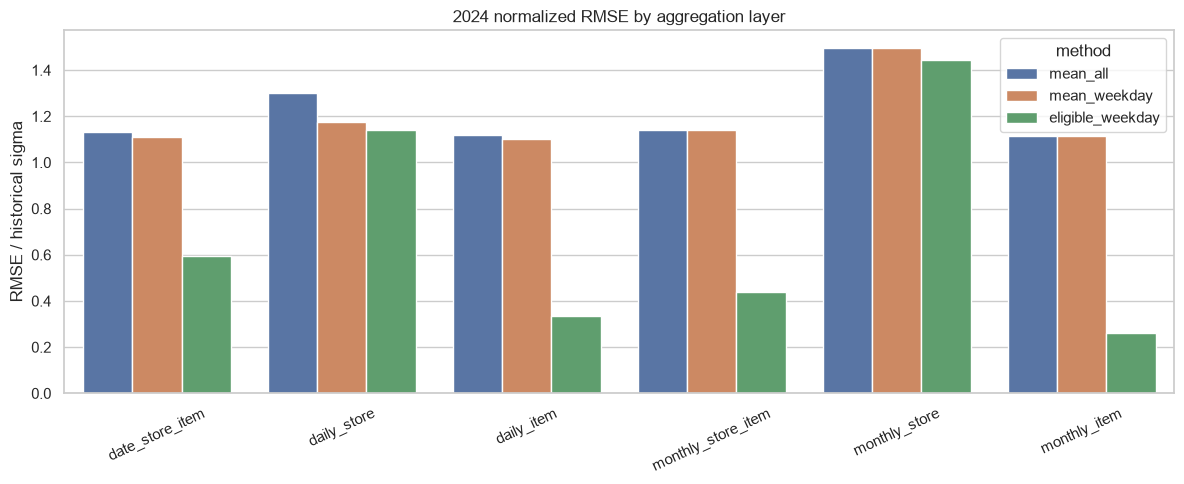

In [4]:
tables=[]; totals={}
for name in ['mean_all','mean_weekday','eligible_weekday']:
    frame=valid[['date','month','store_id','item_id','actual']].copy();frame['prediction']=valid[name].to_numpy()
    metrics,total=score(frame,sigmas);metrics['method']=name;tables.append(metrics.reset_index());totals[name]=total
    print(name,'composite:',round(total,5))
result=pd.concat(tables,ignore_index=True)
display(result.pivot(index='layer',columns='method',values='normalized_rmse'))
display(result.pivot(index='layer',columns='method',values='bias'))
display(pd.DataFrame({'composite':totals}).sort_values('composite'))
fig,ax=plt.subplots(figsize=(12,5));sns.barplot(data=result,x='layer',y='normalized_rmse',hue='method',ax=ax);ax.set(title='2024 normalized RMSE by aggregation layer',ylabel='RMSE / historical sigma',xlabel='');ax.tick_params(axis='x',rotation=25);plt.tight_layout();plt.show()

## 数式の検証と参考値の制約
2024年の行数 N・各層行数 n により W = sqrt(N / (6n)) / sigma とすると、全層を結合した加重 RMSE は上の正規化 RMSE の二乗平均平方根に一致する。

In [5]:
one=result[result.method.eq('mean_all')].set_index('layer')
N=int(one.rows.sum());weights=np.sqrt(N/(len(LAYERS)*one.rows))/one.sigma
weighted_rmse=float(np.sqrt(((one.rmse*weights)**2*one.rows).sum()/N))
print('N=',N,'weighted RMSE=',weighted_rmse,'normalized composite=',totals['mean_all'])
assert np.isclose(weighted_rmse,totals['mean_all'])
display(pd.DataFrame({'validation_rows':one.rows,'sigma_2023':one.sigma,'recomputed_weight_2024':weights}))

N= 353052 weighted RMSE= 1.2246679535829723 normalized composite= 1.2246679535829725


,validation_rows,sigma_2023,recomputed_weight_2024
layer,,,
date_store_item,307440,"5,873.09222",0.00007
daily_store,3660,"96,842.82654",0.00004
daily_item,30744,"49,748.45462",0.00003
monthly_store_item,10080,"154,602.36402",0.00002
monthly_store,120,"2,038,473.12727",0.00001
monthly_item,1008,"1,434,210.61156",0.00001


## 誤差の構造：店舗・商品種別・月

販売条件と曜日を考慮した単純予測の誤差を調べる。表の誤差は予測−実績。検証期間を使った事後分析であり、この結果だけを用いてモデルを何度も調整すると2024年に過学習する。

,rows,actual,prediction,bias,rmse,relative_total_error
store_id,,,,,,
S001,30744,"294,365,842.00000","231,504,733.28023","-2,044.66266","4,950.06291",-0.21355
S004,30744,"318,178,833.00000","257,096,686.88756","-1,986.79892","4,885.08117",-0.19197
S010,30744,"292,517,248.00000","252,002,216.85624","-1,317.81912","3,936.04839",-0.13850
S003,30744,"263,976,098.00000","231,018,632.78673","-1,071.99666","3,572.59526",-0.12485
S002,30744,"227,324,744.00000","208,864,940.48456",-600.43597,"2,944.61707",-0.08120
S005,30744,"204,198,080.00000","197,844,417.91103",-206.66348,"2,928.29811",-0.03112
S006,30744,"146,174,636.00000","145,620,151.99100",-18.03552,"2,486.29425",-0.00379
S007,30744,"174,444,373.00000","184,054,227.32717",312.57658,"2,813.27669",0.05509
S008,30744,"160,743,767.00000","175,143,099.15076",468.36235,"2,591.42330",0.08958


rows              actual  ...         bias        rmse
menu_type     category                              ...                         
collaboration dessert    14640     5,745,017.00000  ...    -69.22490   904.45803
              kids        7320     2,361,245.00000  ...    -12.31183   686.09595
              main       14640    35,839,331.00000  ...   -341.68902 3,247.27025
              side        7320     3,145,300.00000  ...    -63.17842   753.68889
core          dessert    43920    91,361,387.00000  ...   -217.89327 1,127.03197
              drink_bar   7320   285,633,620.00000  ... -1,763.79771 9,589.49881
              kids       21960    69,337,627.00000  ...     44.62017 1,633.91036
              lunch      43920   216,406,475.00000  ...   -298.37992 2,237.82093
              main       54900 1,061,121,736.00000  ... -1,818.61753 5,738.53145
              side       43920   155,087,860.00000  ...   -196.91475 1,435.62880
seasonal      dessert    14640    20,459,348.00000  ...   -172.09301 1,237.86896
              main       29280   260,857,535.00000  ...   -966.26699 4,710.54313
              side        3660     6,624,830.00000  ...   -146.29969 1,215.97253

[13 rows x 5 columns]

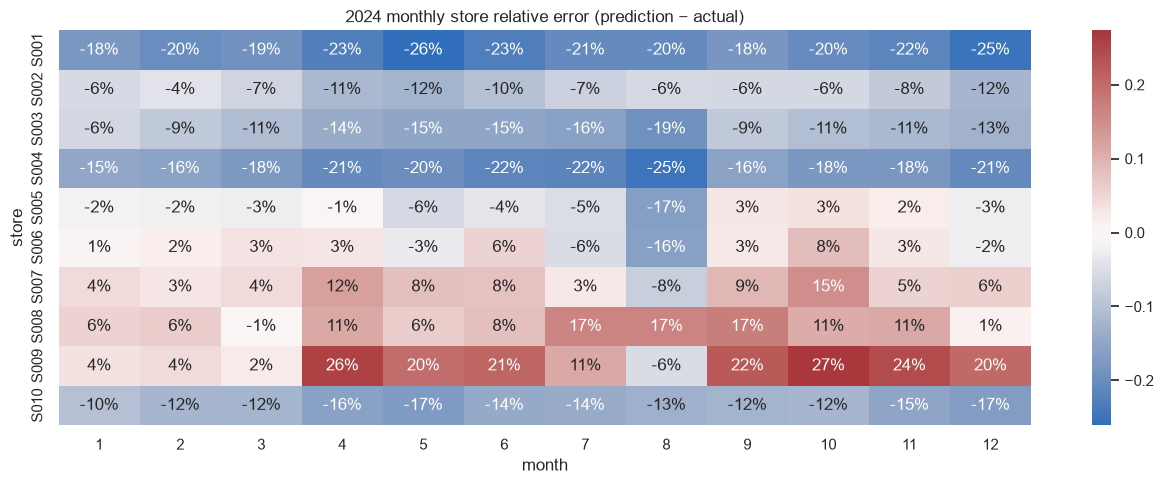

In [6]:
diag=valid.copy()
diag['error']=diag.eligible_weekday-diag.actual
diag['abs_error']=diag.error.abs()
diag['sq_error']=diag.error**2
store_error=diag.groupby('store_id').agg(rows=('actual','size'),actual=('actual','sum'),prediction=('eligible_weekday','sum'),bias=('error','mean'),rmse=('sq_error',lambda x:np.sqrt(x.mean())))
store_error['relative_total_error']=(store_error.prediction-store_error.actual)/store_error.actual
display(store_error.sort_values('relative_total_error'))
category=diag.merge(pd.read_csv(INPUT/'menus.csv')[['item_id','category']],on='item_id',validate='many_to_one')
display(category.groupby(['menu_type','category'],observed=True).agg(rows=('actual','size'),actual=('actual','sum'),prediction=('eligible_weekday','sum'),bias=('error','mean'),rmse=('sq_error',lambda x:np.sqrt(x.mean()))))
month_error=diag.groupby(['month','store_id'],observed=True)[['actual','eligible_weekday']].sum().reset_index()
month_error['month_num']=month_error.month.dt.month
month_error['relative_error']=(month_error.eligible_weekday-month_error.actual)/month_error.actual
fig,ax=plt.subplots(figsize=(13,5));sns.heatmap(month_error.pivot(index='store_id',columns='month_num',values='relative_error').astype(float),center=0,cmap='vlag',annot=True,fmt='.0%',ax=ax);ax.set(title='2024 monthly store relative error (prediction − actual)',xlabel='month',ylabel='store');plt.tight_layout();plt.show()

## 注意
- sigma は2022年からの単純平均による2023年予測の誤差であり、2024年検証の正解を使っていない。
- 検証の販売計画は2023年末に利用可能と仮定する。将来の天候実績や来店・注文実績は使っていない。
- 2024年は閏年で、日次の行数・層別重みは2025年と異なる。2024年の検証値を本番スコアと同一視しない。
- 比較は2024年の1期間に限られる。手法をこの結果に合わせ過ぎると過学習する。